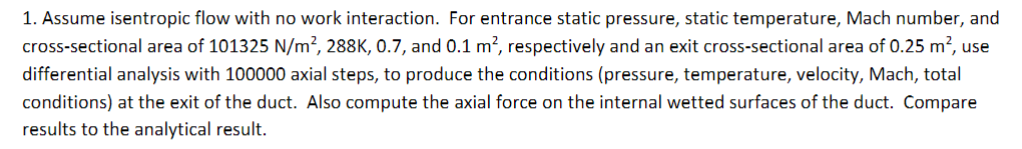

In [19]:
import numpy as np
from quasi_1D import quasi_1D_flow
import matplotlib.pyplot as plt

import scipy as sp

# Numerical

In [20]:
Pi = 101325
Ti = 288
Mi = 0.7
ui = Mi * np.sqrt(1.4*287*Ti)

L_tube = 1
axial_steps = 100_000

Ai = 0.1
Ae = 0.25

xlist = np.linspace(0,L_tube,axial_steps+1)
Af = lambda x: (Ae - Ai) * x + Ai

[uout,Tout,Pout], M, x_break, A_break, Thrust = quasi_1D_flow(inlet = [ui,Ti,Pi], Af = Af,N = axial_steps)

0.0


In [21]:
gamma = 1.4
Tt = Tout*(1+(gamma-1)/2*M**2)
Pt = Pout*(1+(gamma-1)/2*M**2)**(gamma/(gamma-1))


print(f'exit Mach =             {M[-1]}')
print(f'exit Velocity =         {uout[-1]} m/s\n')

print(f'exit Temp =             {Tout[-1]} k')
print(f'exit Total Temp =       {Tt[-1]} k\n')

print(f'exit Pressure =         {Pout[-1]} Pa')
print(f'exit Total Pressure =   {Pt[-1]} Pa\n')

# print(f'exit end area = {A_break}')
print(f'{Thrust =                } N')


exit Mach =             0.217581968268092
exit Velocity =         77.19320438879573 m/s

exit Temp =             313.25816833506855 k
exit Total Temp =       316.22421652014094 k

exit Pressure =         135988.1345596401 Pa
exit Total Pressure =   140548.2815197218 Pa

Thrust =                19166.918110704002 N


# Analytical

In [22]:
R = 287

G_noz = lambda M: 1/M*(2/(gamma+1)*(1+(gamma-1)/2*M**2))**((gamma+1)/(2*(gamma-1)))
G2G1 = Ae / Ai
G1 = G_noz(Mi)
G2 = G2G1 * G1

func = lambda M: G_noz(M) - G2

Me = sp.optimize.fsolve(func, 0.2)[0]

Tte = Ti*(1+(gamma-1)/2*Mi**2)
Pte = Pi*((1+(gamma-1)/2*Mi**2)**(gamma/(gamma-1)))

Te = Tte / (1+(gamma-1)/2*Me**2)
Pe = Pte / ((1+(gamma-1)/2*Me**2)**(gamma/(gamma-1)))

ue = Me * np.sqrt(gamma*R*Te)

rho0 = Pi/(R*Ti)
rho = Pe / (R*Te)

Thrust_a = (rho*ue**2+Pe)*Ae - (rho0*ui**2+Pi)*Ai

In [23]:
print(f'exit Mach =             {Me}')
print(f'exit Velocity =         {ue} m/s\n')

print(f'exit Temp =             {Te} k')
print(f'exit Total Temp =       {Tte} k\n')

print(f'exit Pressure =         {Pe} Pa')
print(f'exit Total Pressure =   {Pte} Pa\n')

print(f'{Thrust_a =              } N')

exit Mach =             0.21758529845936578
exit Velocity =         77.19434835632437 m/s

exit Temp =             313.257863903356 k
exit Total Temp =       316.22399999999993 k

exit Pressure =         135987.76711331183 Pa
exit Total Pressure =   140548.04299085928 Pa

Thrust_a =              19166.88811346253 N


# Error

In [24]:
print(f'exit Mach error =           {M[-1]-Me}')
print(f'exit Velocity error =       {uout[-1]-ue} m/s\n')

print(f'exit Temp error =           {Tout[-1]-Te} k')
print(f'exit Total Temp error =     {Tt[-1]-Tte} k\n')

print(f'exit Pressure error =       {Pout[-1]-Pe} Pa')
print(f'exit Total Pressure error = {Pt[-1]-Pte} Pa\n')

# print(f'exit end area = {A_break}')
print(f'Thrust Error =              {Thrust - Thrust_a} N')

exit Mach error =           -3.330191273770433e-06
exit Velocity error =       -0.0011439675286339934 m/s

exit Temp error =           0.0003044317125500129 k
exit Total Temp error =     0.00021652014100936867 k

exit Pressure error =       0.3674463282804936 Pa
exit Total Pressure error = 0.23852886250824668 Pa

Thrust Error =              0.02999724147230154 N
